# Demo 7: **Biểu diễn trực quan dữ liệu**
<u>Nội dung</u>:
1. Vẽ biểu đồ với thư viện **matplotlib**
    * Dot plot, line plot, radar plot
    * Area plot
    * Bar plot
    * Pie plot
    * Histogram
    * Density plot
    * Box plot
    * Scatter plot
    * Heatmap
    * Subplots

2. Vẽ biểu đồ với thư viện <b>seaborn</b>
3. Vẽ biểu đồ với thư viện **pyplot**


<u>Cập nhật</u>: **10/2026**

---
#### **MÔI TRƯỜNG TRIỂN KHAI ỨNG DỤNG**
---

In [1]:
## Thư mục làm việc
import sys
folder = 'C:/Users/DELL/Documents/Storage/UEH/Biểu diễn trực quan dữ liệu/SPROJECT6_UEH_DATA-VISUALISATION/'
if folder not in sys.path:
    sys.path.append(folder)

In [2]:
%pip install plotly

## Các thư viện tính toán
import numpy                 as np
import pandas                as pd

## Các thư viện biểu diễn trực quan
import matplotlib.pyplot     as plt  # https://matplotlib.org/2.1.2/api/_as_gen/matplotlib.pyplot.plot.html
import plotly.express        as px   # https://plotly.com/graphs/
import plotly.graph_objects  as go
import seaborn               as sbn  # https://seaborn.pydata.org/

## Các thư viện khác
import warnings
warnings.filterwarnings('ignore')

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


---
#### **1. Vẽ biểu đồ với thư viện matplotlib**
---


#####<i>DOT plot, LINE plot, RADAR plot</i>


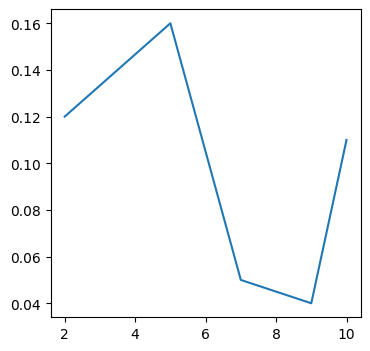

In [3]:
##------------------------------------------------------------------------------
## Sử dụng pyplot.plot(): dạng LINE (default)
##------------------------------------------------------------------------------
x_ = [2, 5, 7, 9, 10] # Giá trị biến độc lập: sắp xếp TĂNG DẦN
y_ = [0.12, 0.16, 0.05, 0.04, 0.11]

plt.figure(figsize = (4, 4))
plt.plot(x_, y_)

plt.show()

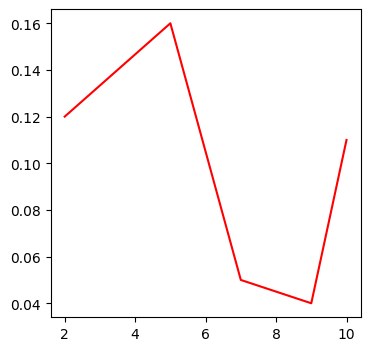

In [4]:
##----------------------------------------------------------------------------------------
## Mầu sắc của line: b(lue), g(reen), r(ed), c(yan), m(agenta), y(ellow), blac(k), w(hite)
##----------------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.plot(x_, y_, 'r')

plt.show()

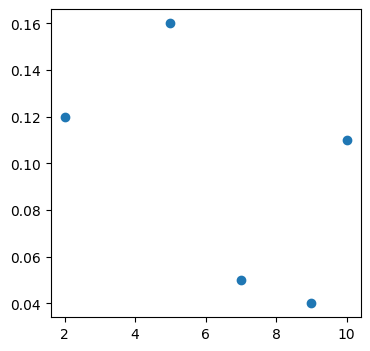

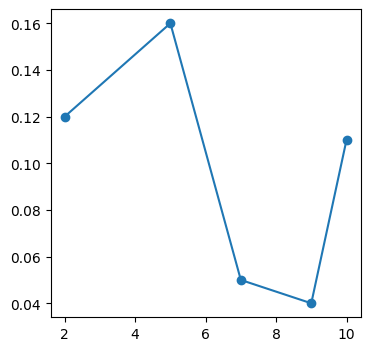

In [5]:
##------------------------------------------------------------------------------
## Dạng DOT (marker)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.plot(x_, y_, 'o')

plt.figure(figsize = (4, 4))
plt.plot(x_, y_, 'o', linestyle = '-')

plt.show()

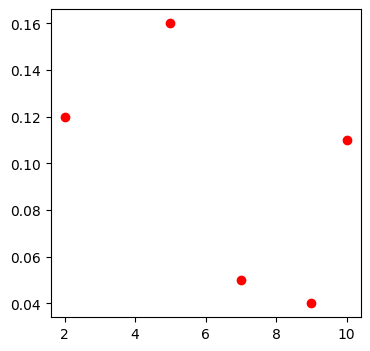

In [6]:
##------------------------------------------------------------------------------
## Chỉ định mầu sắc của marker
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.plot(x_, y_, 'ro') # 'or' cho kết quả tương tự

plt.show()

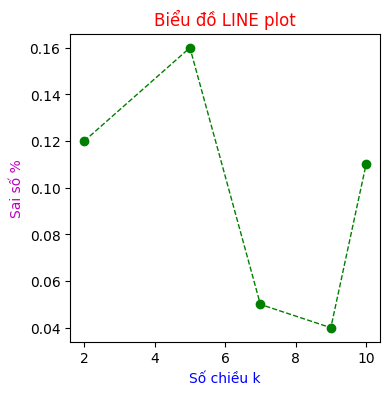

In [7]:
##------------------------------------------------------------------------------
## Sử dụng thêm những thành phần khác của biểu đồ
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.plot(x_, y_, color = 'green', marker = 'o',
         linestyle = 'dashed', linewidth = 1, markersize = 6)
plt.title('Biểu đồ LINE plot', color = 'red')
plt.xlabel('Số chiều k', color = 'blue')
plt.ylabel('Sai số %', color = 'm')

plt.show()

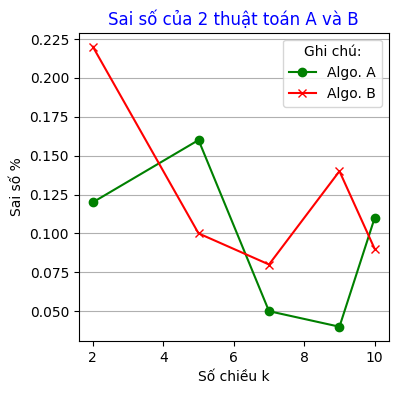

In [8]:
##------------------------------------------------------------------------------
## Biểu đồ MULTIPLE lines: nhiều biến phụ thuộc
##------------------------------------------------------------------------------
k  = [2, 5, 7, 9, 10]
yA = [0.12, 0.16, 0.05, 0.04, 0.11] # số liệu thuật toán A
yB = [0.22, 0.10, 0.08, 0.14, 0.09] # số liệu thuật toán B

plt.figure(figsize = (4, 4))
plt.title('Sai số của 2 thuật toán A và B', color = 'b')
plt.plot(k, yA, color = 'green', label = 'Algo. A', marker = 'o')
plt.plot(k, yB, color = 'red',   label = 'Algo. B', marker = 'x')
plt.grid(axis = 'y') # 'x', 'both'
plt.xlabel('Số chiều k')
plt.ylabel('Sai số %')
plt.legend(title = 'Ghi chú:')

plt.show()

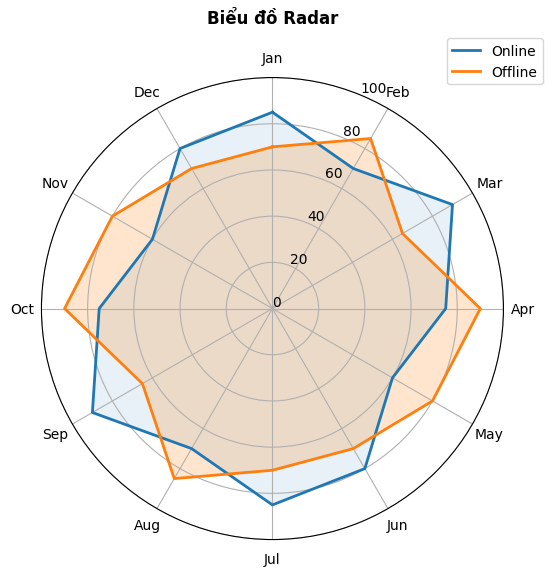

In [9]:
##------------------------------------------------------------------------------
## Biểu đồ RADAR: chuyển line plot vào trong hệ tọa độ cực
##------------------------------------------------------------------------------
thang   = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
Online  = [85, 70, 90, 75, 60, 80, 85, 70, 90, 75, 60, 80]
Offline = [70, 85, 65, 90, 80, 70, 70, 85, 65, 90, 80, 70]

## Chuyển tọa độ của [thang] sang radian (chia đều 2*PI cho 12)
thg_rad = np.linspace(0, 2 * np.pi, len(thang), endpoint = False).tolist()

## Đóng kín đường biểu diễn bằng cách lặp lại điểm đầu tiên ở cuối danh sách
thg_rad += thg_rad[:1]
Online  += Online[:1]
Offline += Offline[:1]

## Tạo khung hình và hệ trục tọa độ cực
plt.figure(figsize = (6, 6))
ax = plt.axes(projection = 'polar')
ax.set_theta_direction(-1)       # -1: Theo chiều kim đồng hồ (1: Ngược chiều)
ax.set_theta_offset(np.pi / 2)   # Đặt vị trí gốc tọa độ 0 radian ở góc 12 giờ

## Vẽ đường biểu diễn
ax.plot(thg_rad, Online,  color = '#1f77b4', linewidth = 2, label = 'Online')
ax.fill(thg_rad, Online,  color = '#1f77b4', alpha = 0.1)  # alpha: độ mờ/đậm
ax.plot(thg_rad, Offline, color = '#ff7f0e', linewidth = 2, label = 'Offline')
ax.fill(thg_rad, Offline, color = '#ff7f0e', alpha = 0.2)

## Bổ sung các thành phần của biểu đồ
ax.set_xticks(thg_rad[:-1])
ax.set_xticklabels(thang, fontsize = 10)
ax.set_yticks([0, 20, 40, 60, 80, 100])
plt.legend(loc = 'upper right', bbox_to_anchor = (1.1, 1.1))  # bbox_to_anchor: tọa độ (x, y)
plt.title('Biểu đồ Radar', fontweight = 'bold', size = 12, y = 1.1)  # y: khoảng cách giữa tiêu đề và biểu đồ

plt.show()

#####<i>AREA plot</i>

In [10]:
## Tạo dữ liệu giả lập doanh số của các sản phẩm A, B và C tại 200 mốc thời điểm trong 12 tháng
tdiem = np.linspace(1, 12, 200)
sph_a = 50 + 10 * np.sin(tdiem) + 30 * np.exp(-(tdiem - 4)**2 / 1.5) + 40 * np.exp(-(tdiem - 8.5)**2 / 1.5)
sph_b = 60 + 20 * np.cos(tdiem * 1.2)
sph_c = 40 + 15 * np.sin(tdiem / 1.5) + 2.5 * tdiem

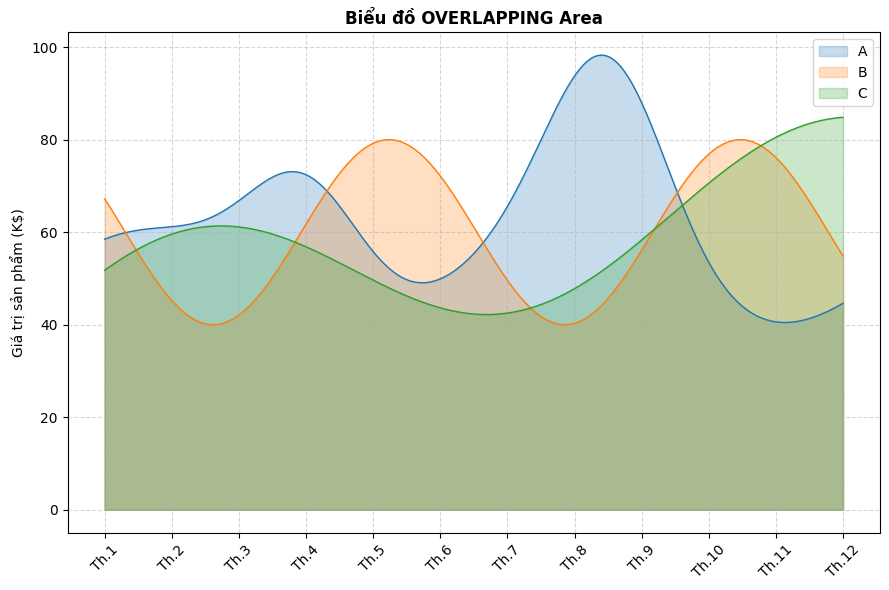

In [11]:
##------------------------------------------------------------------------------
## Biểu đồ Overlapping Area
##------------------------------------------------------------------------------
plt.figure(figsize = (9, 6))

## Vẽ các đường biểu diễn
plt.plot(tdiem, sph_a, color = '#1f77b4', linewidth = 1.0)
plt.fill_between(tdiem, sph_a, color = '#1f77b4', alpha = 0.25, label = 'A')

plt.plot(tdiem, sph_b, color = '#ff7f0e', linewidth = 1.0)
plt.fill_between(tdiem, sph_b, color = '#ff7f0e', alpha = 0.25, label = 'B')

plt.plot(tdiem, sph_c, color = '#2ca02c', linewidth = 1.0)
plt.fill_between(tdiem, sph_c, color = '#2ca02c', alpha = 0.25, label = 'C')

## Bổ sung các thành phần của biểu đồ
plt.title('Biểu đồ OVERLAPPING Area', fontsize = 12, fontweight = 'bold')
plt.xticks(list(range(1, 13)), [f"Th.{i}" for i in range(1, 13)], rotation = 45)
plt.ylabel('Giá trị sản phẩm (K$)', fontsize = 10)
plt.legend(loc = 'upper right')
plt.grid(True, linestyle='--', alpha = 0.5)
plt.tight_layout()

plt.show()

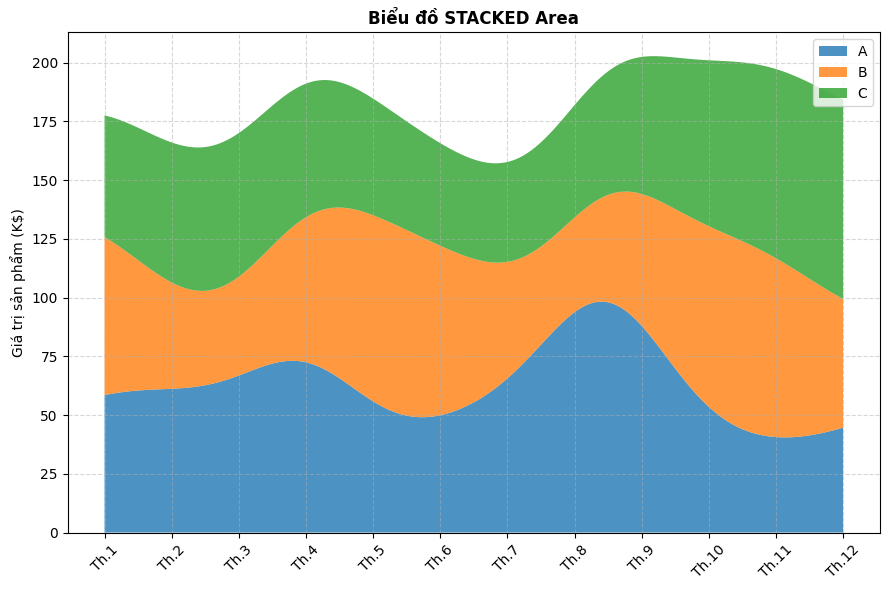

In [12]:
##------------------------------------------------------------------------------
## Biểu đồ Stacked Area
##------------------------------------------------------------------------------
plt.figure(figsize = (9, 6))

## Vẽ các đường biểu diễn
plt.stackplot(tdiem, sph_a, sph_b, sph_c, labels = ['A', 'B', 'C'],
              colors   = ['#1f77b4', '#ff7f0e', '#2ca02c'],
              alpha    = 0.8,    # độ đậm/nhạt
              baseline = 'zero'  # Trục tung từ y = 0
)

## Bổ sung các thành phần của biểu đồ
plt.title('Biểu đồ STACKED Area', fontsize = 12, fontweight = 'bold')
plt.xticks(list(range(1, 13)), [f"Th.{i}" for i in range(1, 13)], rotation = 45)
plt.ylabel('Giá trị sản phẩm (K$)', fontsize = 10)
plt.legend(loc = 'upper right')
plt.grid(True, linestyle='--', alpha = 0.5)
plt.tight_layout()

plt.show()

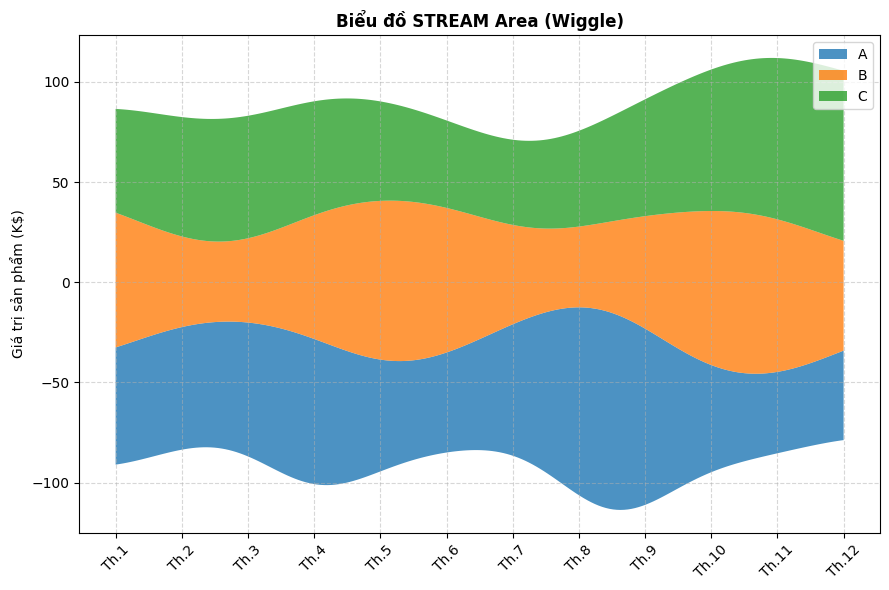

In [13]:
##------------------------------------------------------------------------------
## Biểu đồ Stream Area (Wiggle)
##------------------------------------------------------------------------------
plt.figure(figsize = (9, 6))

## Vẽ các đường biểu diễn
plt.stackplot(tdiem, sph_a, sph_b, sph_c, labels = ['A', 'B', 'C'],
              colors   = ['#1f77b4', '#ff7f0e', '#2ca02c'],
              alpha    = 0.8,
              baseline ='wiggle'
)

## Bổ sung các thành phần của biểu đồ
plt.title('Biểu đồ STREAM Area (Wiggle)', fontsize = 12, fontweight = 'bold')
plt.xticks(list(range(1, 13)), [f"Th.{i}" for i in range(1, 13)], rotation = 45)
plt.ylabel('Giá trị sản phẩm (K$)', fontsize = 10)
plt.legend(loc = 'upper right')
plt.grid(True, linestyle='--', alpha = 0.5)
plt.tight_layout()

plt.show()

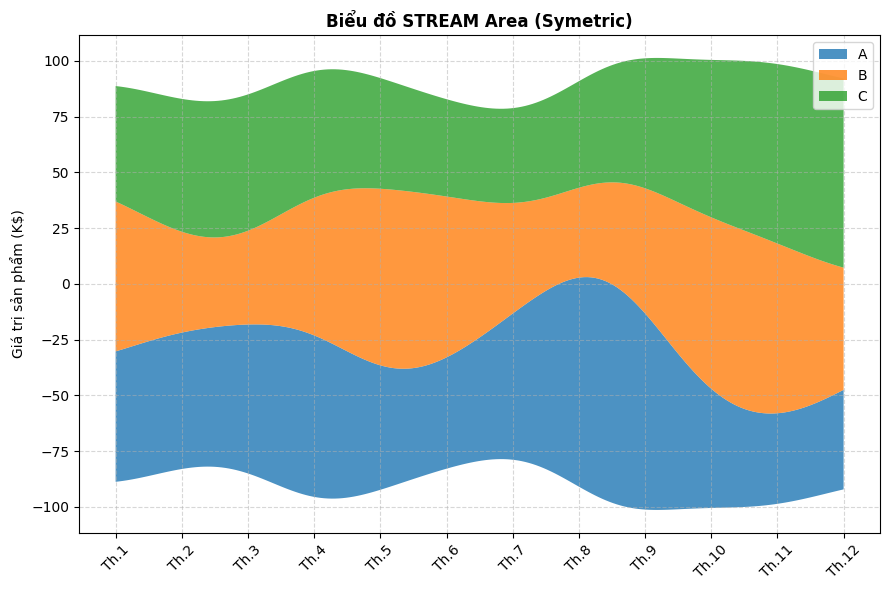

In [14]:
##------------------------------------------------------------------------------
## Biểu đồ Stream Area (Symetric)
##------------------------------------------------------------------------------
plt.figure(figsize = (9, 6))

## Vẽ các đường biểu diễn
plt.stackplot(tdiem, sph_a, sph_b, sph_c, labels = ['A', 'B', 'C'],
              colors   = ['#1f77b4', '#ff7f0e', '#2ca02c'],
              alpha    = 0.8,
              baseline ='sym'
)

## Bổ sung các thành phần của biểu đồ
plt.title('Biểu đồ STREAM Area (Symetric)', fontsize = 12, fontweight = 'bold')
plt.xticks(list(range(1, 13)), [f"Th.{i}" for i in range(1, 13)], rotation = 45)
plt.ylabel('Giá trị sản phẩm (K$)', fontsize = 10)
plt.legend(loc = 'upper right')
plt.grid(True, linestyle='--', alpha = 0.5)
plt.tight_layout()

plt.show()

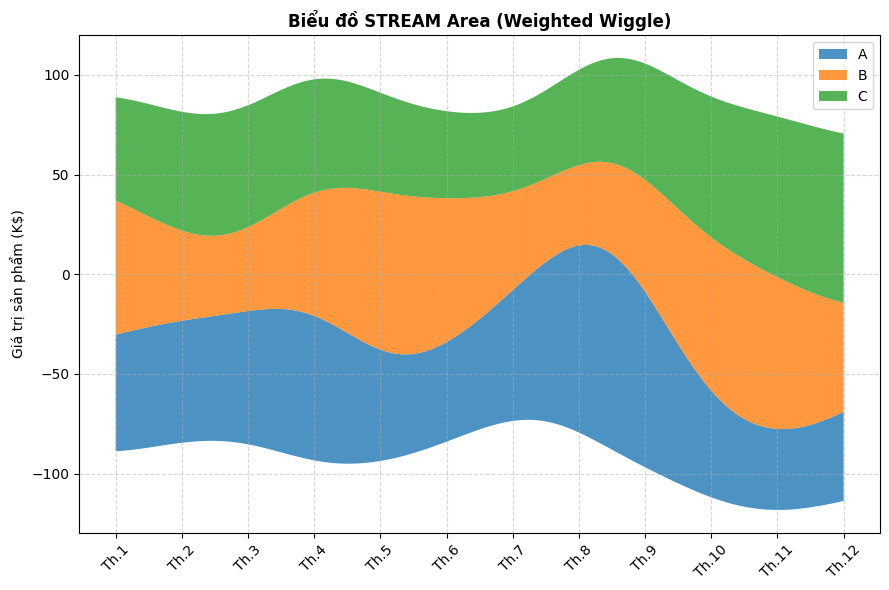

In [15]:
##------------------------------------------------------------------------------
## Biểu đồ Stream Area (Weighted_Wiggle)
##------------------------------------------------------------------------------
plt.figure(figsize = (9, 6))

## Vẽ các đường biểu diễn
plt.stackplot(tdiem, sph_a, sph_b, sph_c, labels = ['A', 'B', 'C'],
              colors   = ['#1f77b4', '#ff7f0e', '#2ca02c'],
              alpha    = 0.8,
              baseline ='weighted_wiggle'
)

## Bổ sung các thành phần của biểu đồ
plt.title('Biểu đồ STREAM Area (Weighted Wiggle)', fontsize = 12, fontweight = 'bold')
plt.xticks(list(range(1, 13)), [f"Th.{i}" for i in range(1, 13)], rotation = 45)
plt.ylabel('Giá trị sản phẩm (K$)', fontsize = 10)
plt.legend(loc = 'upper right')
plt.grid(True, linestyle='--', alpha = 0.5)
plt.tight_layout()

plt.show()

#####<i>BAR plot</i>

In [16]:
## Dữ liệu
x_         = ['A', 'B', 'C', 'D', 'E']
y1, y2, y3 = [4, 3, 5, 3, 2], [6, 4, 3, 2, 4], [2, 2, 5, 3, 2]

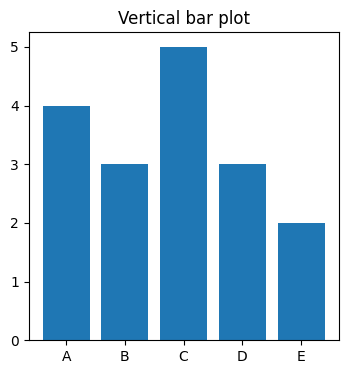

In [17]:
##------------------------------------------------------------------------------
## Các cột ĐỨNG (Vertical)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.title('Vertical bar plot')
plt.bar(x_, y1)

plt.show()

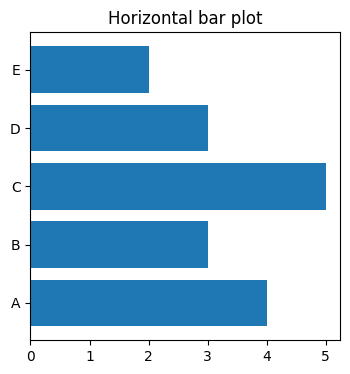

In [18]:
##------------------------------------------------------------------------------
## Các cột nằm NGANG (Horizontal)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.title('Horizontal bar plot')
plt.barh(x_, y1)

plt.show()

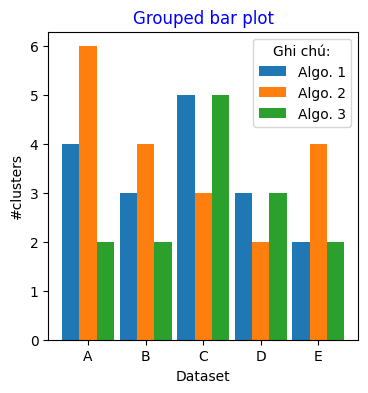

In [19]:
##------------------------------------------------------------------------------
## Hai biến độc lập: trình bày theo NHÓM (Grouped)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.title('Grouped bar plot', color = 'blue')
idx = np.arange(5)  # chỉ số cho 'nhóm cột'
width = 0.30  # độ rộng cột
plt.bar(idx, y1, width, label = 'Algo. 1')
plt.bar(idx + width, y2, width, label = 'Algo. 2')
plt.bar(idx + (width * 2), y3, width, label = 'Algo. 3')
plt.xlabel('Dataset')
plt.xticks(idx + width, x_)  # <vị trí>, <điểm dữ liệu trên trục hoành>
plt.ylabel('#clusters')
plt.legend(title = 'Ghi chú:')

plt.show()

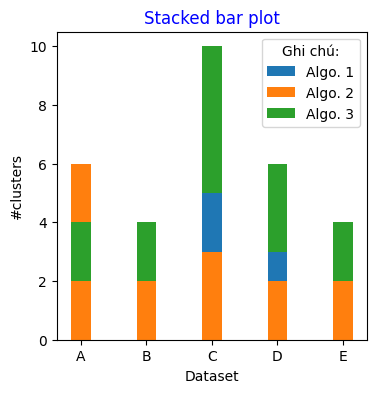

In [20]:
##------------------------------------------------------------------------------
## Hai biến độc lập: trình bày theo NGĂN XẾP (Stacked)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.title('Stacked bar plot', color = 'b')
plt.bar(idx, y1, width, label = 'Algo. 1')
plt.bar(idx, y2, width, label = 'Algo. 2')
plt.bar(idx, y3, width, label = 'Algo. 3', bottom = y3)
plt.xlabel('Dataset')
plt.xticks(idx, x_) # <vị trí>, <điểm dữ liệu trên trục hoành>
plt.ylabel('#clusters')
plt.legend(title = 'Ghi chú:')

plt.show()

#####<i>PIE plot</i>


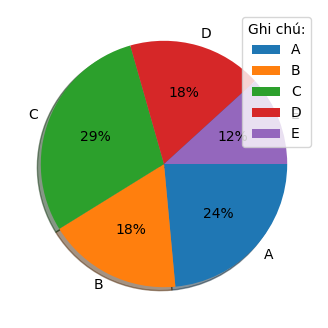

In [21]:
##------------------------------------------------------------------------------
## Sử dụng pyplot.pie(): Biểu diễn tỷ lệ
##------------------------------------------------------------------------------
x_ = ['A', 'B', 'C', 'D', 'E']
y_ = [ 4, 3, 5, 3, 2]

plt.figure(figsize = (4, 4))
plt.pie(y_, labels = x_, autopct = '%.f%%', shadow = True, counterclock = False)
plt.legend(title = 'Ghi chú:', loc = 1) # loc = 0 (default): top-left, 1: top-right
                                        #       3: bottom-left, 4: bottom-right
plt.show()

#####<i>HISTOGRAM</i>

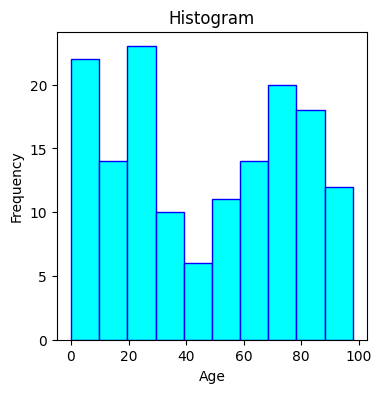

In [22]:
##------------------------------------------------------------------------------
## Biểu diễn tần số (frequency) của biến RỜI RẠC
##------------------------------------------------------------------------------
np.random.seed(1)
freq = np.random.randint(0, 100, 150) # (min, max, n)

plt.figure(figsize = (4, 4))
plt.title('Histogram')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.hist(freq, color = 'cyan', edgecolor = 'blue')

plt.show()

#####<i>DISTRIBUTION plot</i>

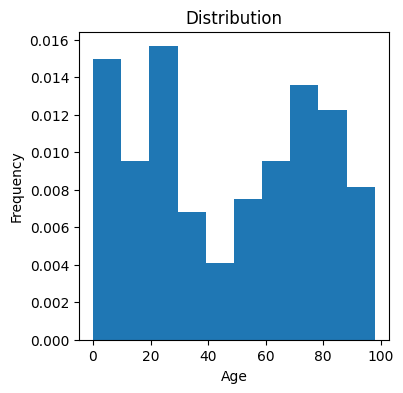

In [23]:
##------------------------------------------------------------------------------
## Biểu diễn phân phối của biến RỜI RẠC
##------------------------------------------------------------------------------
np.random.seed(1)
freq = np.random.randint(0, 100, 150) # (min, max, n)

plt.figure(figsize = (4, 4))
plt.title('Distribution')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.hist(freq, density = True)

plt.show()

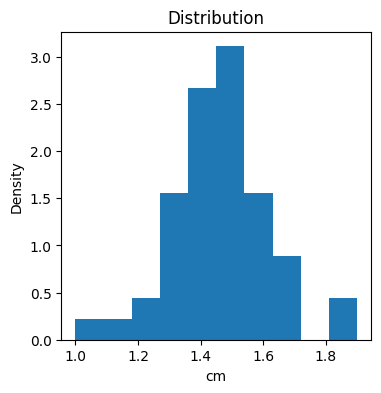

In [24]:
##------------------------------------------------------------------------------
## Biểu diễn phân phối của biến LIÊN TỤC
##------------------------------------------------------------------------------
data = [1.4, 1.4, 1.3, 1.5, 1.4, 1.7, 1.4, 1.5, 1.4, 1.5,
        1.5, 1.6, 1.4, 1.1, 1.2, 1.5, 1.3, 1.4, 1.7, 1.5,
        1.7, 1.5, 1.0, 1.7, 1.9, 1.6, 1.6, 1.5, 1.4, 1.6,
        1.6, 1.5, 1.5, 1.4, 1.5, 1.2, 1.3, 1.5, 1.3, 1.5,
        1.3, 1.3, 1.3, 1.6, 1.9, 1.4, 1.6, 1.4, 1.5, 1.4]

plt.figure(figsize = (4, 4))
plt.title('Distribution')
plt.hist(data, density = True)
plt.xlabel('cm')
plt.ylabel('Density')

plt.show()

#####<i>BOX plot</i>

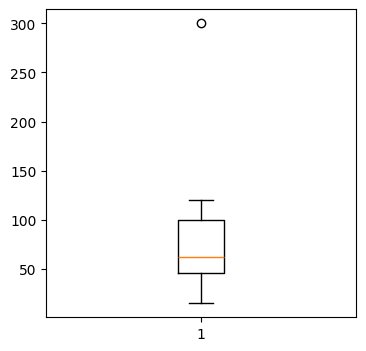

In [25]:
##------------------------------------------------------------------------------
## Biểu đồ hộp dạng ĐỨNG
##------------------------------------------------------------------------------
data = np.array([15, 45, 50, 120, 300, 34, 55, 70, 105, 85])

plt.figure(figsize = (4, 4))
plt.boxplot(data)

plt.show()

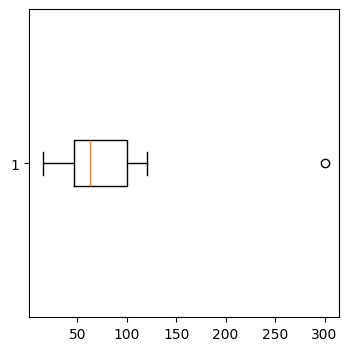

In [26]:
##------------------------------------------------------------------------------
## Biểu đồ hộp dạng nằm NGANG
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.boxplot(data, vert = False)

plt.show()

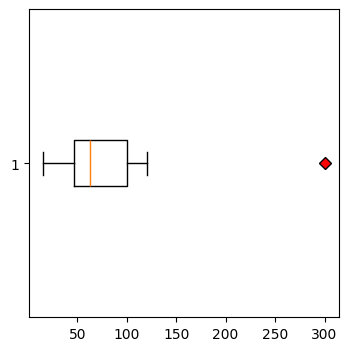

In [27]:
##------------------------------------------------------------------------------
## Chọn ký tự đặc biệt cho outliers
##------------------------------------------------------------------------------
outlier = dict(marker = 'D', markerfacecolor = 'r')

plt.figure(figsize = (4, 4))
plt.boxplot(data, vert = False, flierprops = outlier)

plt.show()

#####<i>SCATTER plot</i>

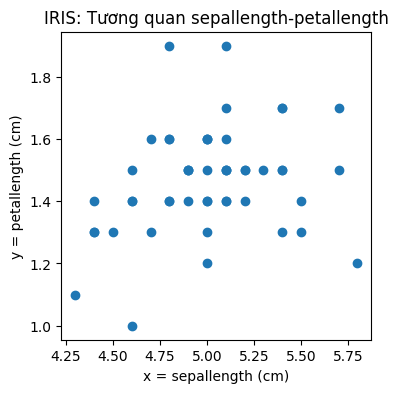

In [28]:
##------------------------------------------------------------------------------
## Biểu đồ phân tán KHÔNG phân lớp
##------------------------------------------------------------------------------
x_ = [5.1, 4.9, 4.7, 4.6, 5.0, 5.4, 4.6, 5.0, 4.4, 4.9,
     5.4, 4.8, 4.8, 4.3, 5.8, 5.7, 5.4, 5.1, 5.7, 5.1,
     5.4, 5.1, 4.6, 5.1, 4.8, 5.0, 5.0, 5.2, 5.2, 4.7,
     4.8, 5.4, 5.2, 5.5, 4.9, 5.0, 5.5, 4.9, 4.4, 5.1,
     5.0, 4.5, 4.4, 5.0, 5.1, 4.8, 5.1, 4.6, 5.3, 5.0]

y_ = [1.4, 1.4, 1.3, 1.5, 1.4, 1.7, 1.4, 1.5, 1.4, 1.5,
     1.5, 1.6, 1.4, 1.1, 1.2, 1.5, 1.3, 1.4, 1.7, 1.5,
     1.7, 1.5, 1.0, 1.7, 1.9, 1.6, 1.6, 1.5, 1.4, 1.6,
     1.6, 1.5, 1.5, 1.4, 1.5, 1.2, 1.3, 1.5, 1.3, 1.5,
     1.3, 1.3, 1.3, 1.6, 1.9, 1.4, 1.6, 1.4, 1.5, 1.4]

plt.figure(figsize = (4, 4))
plt.title('IRIS: Tương quan sepallength-petallength')
plt.xlabel('x = sepallength (cm)')
plt.ylabel('y = petallength (cm)')
plt.scatter(x_, y_)

plt.show()

#####<i>HEAT MAP</i>

In [29]:
## Ma trận tương quan
corr_matrix = [[ 1.0000,  0.0862,  0.2837, -0.0842, -0.0684, -0.0265, -0.0881],
               [ 0.0862,  1.0000,  0.3276,  0.7647,  0.5876, -0.9156,  0.7516],
               [ 0.2837,  0.3276,  1.0000,  0.4413,  0.0228, -0.5441,  0.4715],
               [-0.0842,  0.7647,  0.4413,  1.0000,  0.4869, -0.8340,  0.6229],
               [-0.0684,  0.5876,  0.0228,  0.4869,  1.0000, -0.4616,  0.4398],
               [-0.0265, -0.9156, -0.5441, -0.8340, -0.4616,  1.0000, -0.8724],
               [-0.0881,  0.7516,  0.4715,  0.6229,  0.4398, -0.8724,  1.0000]]

In [30]:
corr_matrix = np.random.random((10, 10))

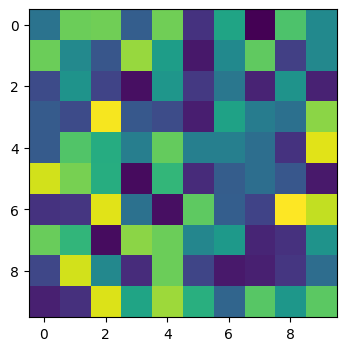

In [31]:
##------------------------------------------------------------------------------
## Biểu diễn mối tương quan
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.imshow(corr_matrix)

plt.show()

#####<i>Subplot</i>

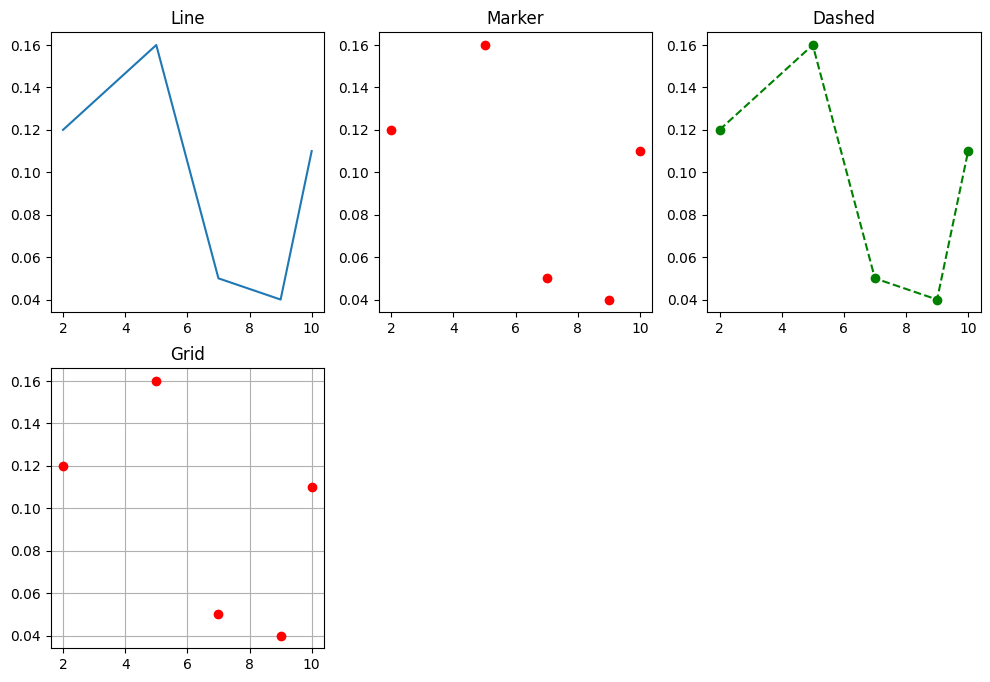

In [32]:
## Sử dụng matplotlib.pyplot.subplots()
x_ = [2, 5, 7, 9, 10] # Giá trị biến độc lập: sắp xếp TĂNG DẦN
y_ = [0.12, 0.16, 0.05, 0.04, 0.11]

plt.figure(figsize = ([12, 8])) # khung (width, height): inch

## Chèn thêm biểu đồ bằng phương thức subplot(<rows>, <cols>, <index>)
plt.subplot(2, 3, 1) # subplot 1 trong ma trận (2 rows, 3 cols)
plt.title('Line')
plt.plot(x_, y_)

plt.subplot(2, 3, 2) # subplot 2 trong ma trận (2 rows, 3 cols)
plt.title('Marker')
plt.plot(x_, y_, 'o', color = 'red')

plt.subplot(2, 3, 3) # subplot 3 trong ma trận (2 rows, 3 cols)
plt.title('Dashed')
plt.plot(x_, y_, color = 'green', marker = 'o', linestyle = 'dashed', label = 'Dashed')

plt.subplot(2, 3, 4) # subplot 4 trong ma trận (2 rows, 3 cols)
plt.title('Grid')
plt.grid(True)
plt.plot(x_, y_, 'o', color = 'red')

plt.show()

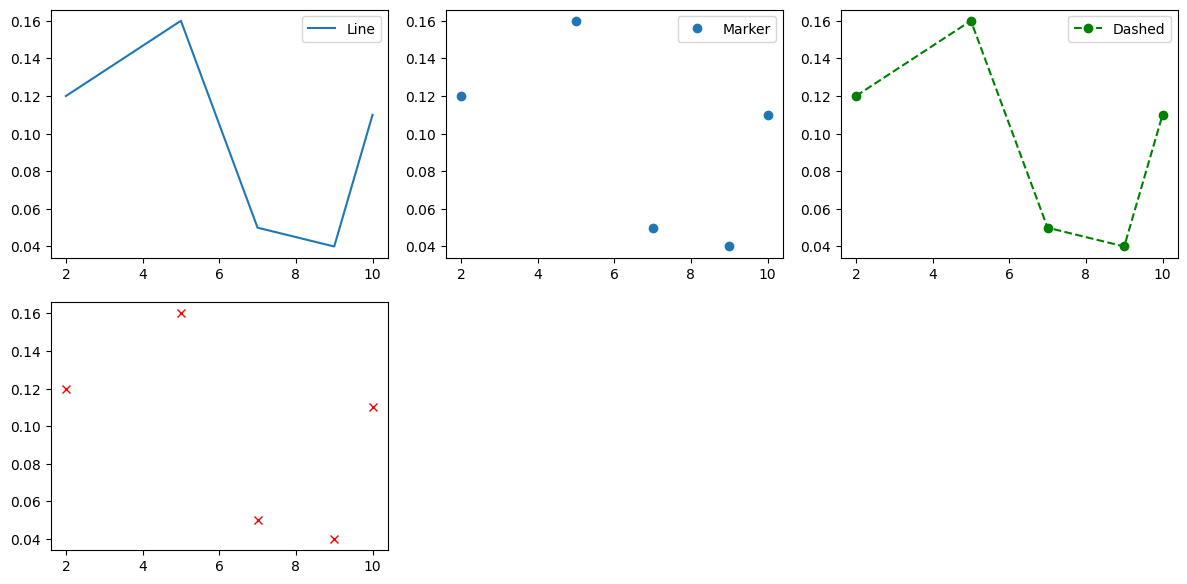

In [33]:
## Sử dụng matplotlib.gridspec.GridSpec()
import matplotlib as plt

# Định nghĩa lưới (grid) chứa các subplots
fig   = plt.pyplot.figure(figsize = ([12, 6]))
grid  = plt.gridspec.GridSpec(nrows = 2, ncols = 3) # lưới có 2 dòng, 3 cột
f_ax1 = fig.add_subplot(grid[0, 0])
f_ax2 = fig.add_subplot(grid[0, 1])
f_ax3 = fig.add_subplot(grid[0, 2])
f_ax4 = fig.add_subplot(grid[1, 0])
fig.tight_layout() # kéo dãn các subplots cho vừa khung hình

## Đặt các biểu đồ vào lưới
f_ax1.plot(x_, y_, label = 'Line')
f_ax1.legend()
f_ax2.plot(x_, y_, 'o', label = 'Marker')
f_ax2.legend()
f_ax3.plot(x_, y_, color = 'green', marker = 'o', linestyle = 'dashed', label = 'Dashed')
f_ax3.legend()
f_ax4.plot(x_, y_, 'x', color = 'red')

plt.pyplot.show()

---
#### **2. Vẽ biểu đồ với thư viện seaborn**

* <i>Thư viện SEABORN hiệu quả với pandas.DataFrame</i>
---

In [34]:
import matplotlib.pyplot  as plt

#####<i>DOT plot, LINE plot</i>

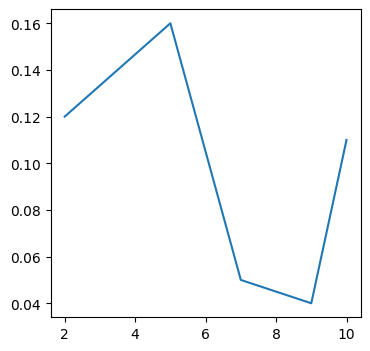

In [35]:
##------------------------------------------------------------------------------
## Sử dụng seaborn.lineplot()
##------------------------------------------------------------------------------
x_ = [2, 5, 7, 9, 10]  # Giá trị biến độc lập: sắp xếp TĂNG DẦN
y_ = [0.12, 0.16, 0.05, 0.04, 0.11]

plt.figure(figsize = (4, 4))
sbn.lineplot(x = x_, y = y_)

plt.show()

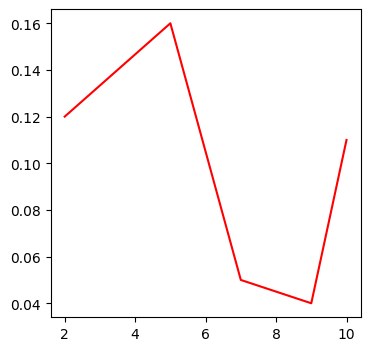

In [36]:
##------------------------------------------------------------------------------
## Mầu sắc của line: b(lue), g(reen), r(ed), c(yan), m(agenta), y(ellow), blac(k), w(hite)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
sbn.lineplot(x = x_, y = y_, color = 'r')

plt.show()

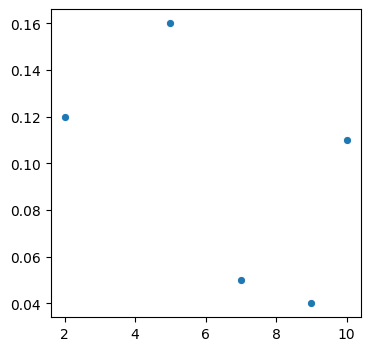

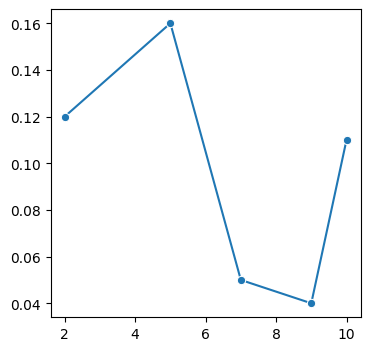

In [37]:
##------------------------------------------------------------------------------
## Dạng DOT (marker)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
sbn.lineplot(x = x_, y = y_, marker = 'o', linestyle = '')

plt.figure(figsize = (4, 4))
sbn.lineplot(x = x_, y = y_, marker = 'o')

plt.show()

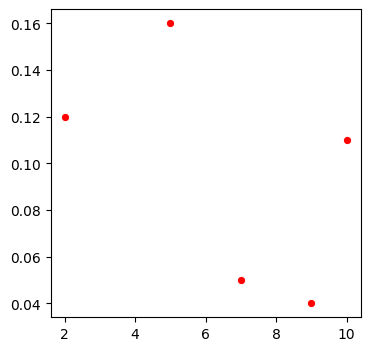

In [38]:
##------------------------------------------------------------------------------
## Chỉ định mầu sắc của marker
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
sbn.lineplot(x = x_, y = y_, marker = 'o', linestyle = '', color = 'red')

plt.show()

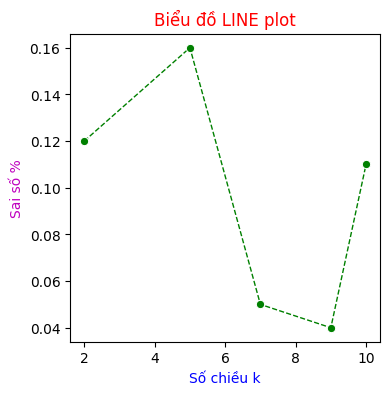

In [39]:
##------------------------------------------------------------------------------
## Sử dụng thêm những thành phần khác của biểu đồ
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
sbn.lineplot(x = x_, y = y_, color = 'green', marker = 'o',
             linestyle = 'dashed', linewidth = 1, markersize = 6)
plt.title('Biểu đồ LINE plot', color = 'red')
plt.xlabel('Số chiều k', color = 'blue')
plt.ylabel('Sai số %', color = 'm')

plt.show()

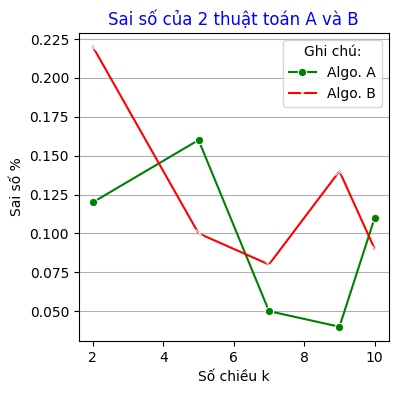

In [40]:
##------------------------------------------------------------------------------
## Biểu đồ MULTIPLE lines: nhiều biến phụ thuộc
##------------------------------------------------------------------------------
k  = [2, 5, 7, 9, 10]
yA = [0.12, 0.16, 0.05, 0.04, 0.11] # số liệu thuật toán A
yB = [0.22, 0.10, 0.08, 0.14, 0.09] # số liệu thuật toán B

plt.figure(figsize = (4, 4))
plt.title('Sai số của 2 thuật toán A và B', color = 'b')
sbn.lineplot(x = k, y = yA, color = 'green', label = 'Algo. A', marker = 'o')
sbn.lineplot(x = k, y = yB, color = 'red',   label = 'Algo. B', marker = 'x')
plt.grid(axis = 'y') # 'x', 'both'
plt.xlabel('Số chiều k')
plt.ylabel('Sai số %')
plt.legend(title = 'Ghi chú:')

plt.show()

#####<i>BAR plot</i>

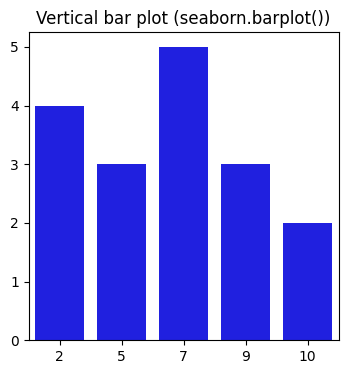

In [41]:
##------------------------------------------------------------------------------
## Các cột ĐỨNG (Vertical)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.title('Vertical bar plot (seaborn.barplot())')
sbn.barplot(x = x_, y = y1, color = 'blue') # không có tham số color: mỗi cột = 1 mầu

plt.show()

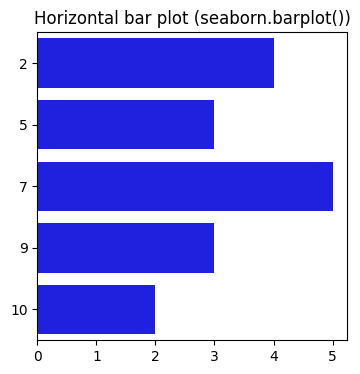

In [42]:
##------------------------------------------------------------------------------
## Các cột nằm NGANG (Horizontal)
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
plt.title('Horizontal bar plot (seaborn.barplot())')
sbn.barplot(x = y1, y = x_, color = 'blue', orient = 'h') # lưu ý: đổi thứ tự x và y

plt.show()

#####<i>HISTOGRAM</i>

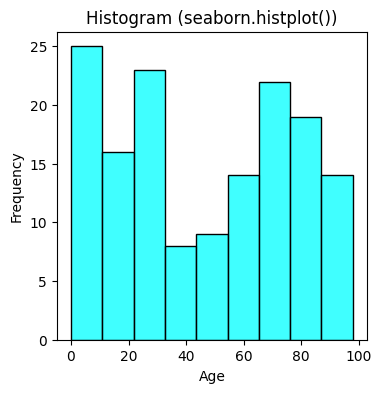

In [43]:
##------------------------------------------------------------------------------
## Biểu diễn tần số (frequency) của biến RỜI RẠC
##------------------------------------------------------------------------------
np.random.seed(1)
freq = np.random.randint(0, 100, 150) # (min, max, n)

plt.figure(figsize = (4, 4))
sbn.histplot(freq, color = 'cyan')
plt.title('Histogram (seaborn.histplot())')
plt.xlabel('Age')
plt.ylabel('Frequency')

plt.show()

#####<i>DISTRIBUTION plot</i>

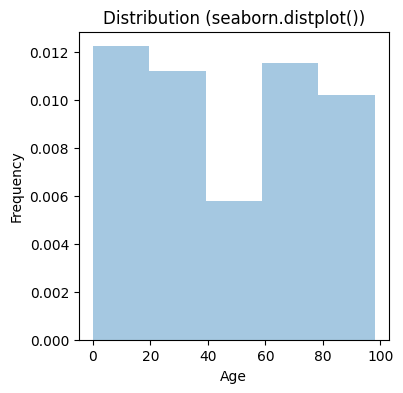

In [44]:
##------------------------------------------------------------------------------
## Biểu diễn phân phối của biến RỜI RẠC
##------------------------------------------------------------------------------
np.random.seed(1)
freq = np.random.randint(0, 100, 150) # (min, max, n)

plt.figure(figsize = (4, 4))
plt.title('Distribution (seaborn.distplot())')
plt.xlabel('Age')
plt.ylabel('Frequency')
sbn.distplot(freq, kde = False, norm_hist = True)

plt.show()

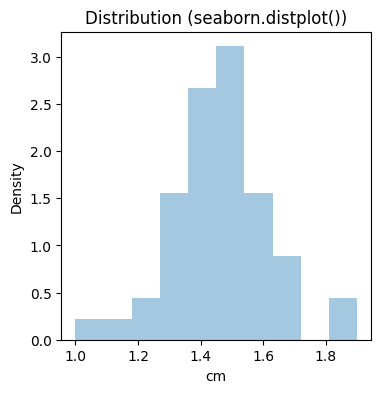

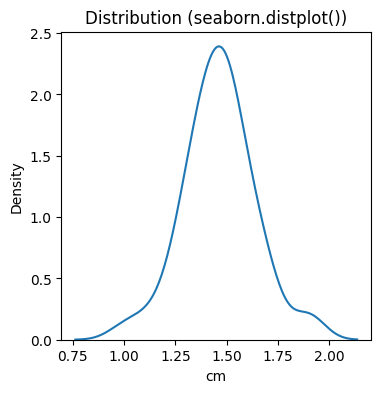

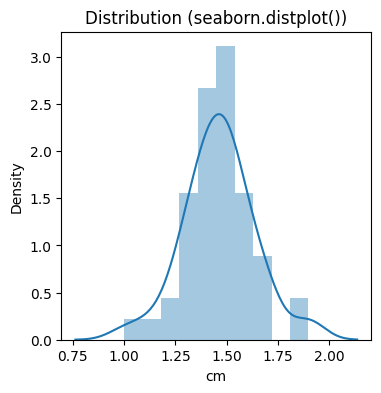

In [45]:
##------------------------------------------------------------------------------
## Biểu diễn phân phối của biến LIÊN TỤC
##------------------------------------------------------------------------------
data = [1.4, 1.4, 1.3, 1.5, 1.4, 1.7, 1.4, 1.5, 1.4, 1.5,
        1.5, 1.6, 1.4, 1.1, 1.2, 1.5, 1.3, 1.4, 1.7, 1.5,
        1.7, 1.5, 1.0, 1.7, 1.9, 1.6, 1.6, 1.5, 1.4, 1.6,
        1.6, 1.5, 1.5, 1.4, 1.5, 1.2, 1.3, 1.5, 1.3, 1.5,
        1.3, 1.3, 1.3, 1.6, 1.9, 1.4, 1.6, 1.4, 1.5, 1.4]

plt.figure(figsize = (4, 4))
plt.title('Distribution (seaborn.distplot())')
plt.xlabel('cm')
plt.ylabel('Density')
sbn.distplot(data, kde = False, norm_hist = True)

## Gaussian Kernel Ddensity Estimate (KDE)
plt.figure(figsize = (4, 4))
plt.title('Distribution (seaborn.distplot())')
plt.xlabel('cm')
plt.ylabel('Density')
sbn.distplot(data, kde = True, norm_hist = True, hist = False)

## Bổ sung histogram
plt.figure(figsize = (4, 4))
plt.title('Distribution (seaborn.distplot())')
plt.xlabel('cm')
plt.ylabel('Density')
sbn.distplot(data, kde = True, norm_hist = True)

plt.show()

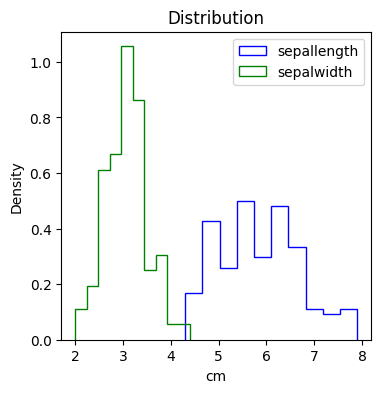

In [46]:
## Sử dụng với DataFrame
df = pd.read_csv(folder + '/Data/Iris.csv')

plt.figure(figsize = (4, 4))
plt.title('Distribution')
plt.hist(df['sepallength'], density = True, histtype = 'step', color = 'blue', label = 'sepallength')
plt.hist(df['sepalwidth'],  density = True, histtype = 'step', color = 'green', label = 'sepalwidth')
plt.xlabel('cm')
plt.ylabel('Density')
plt.legend()

plt.show()

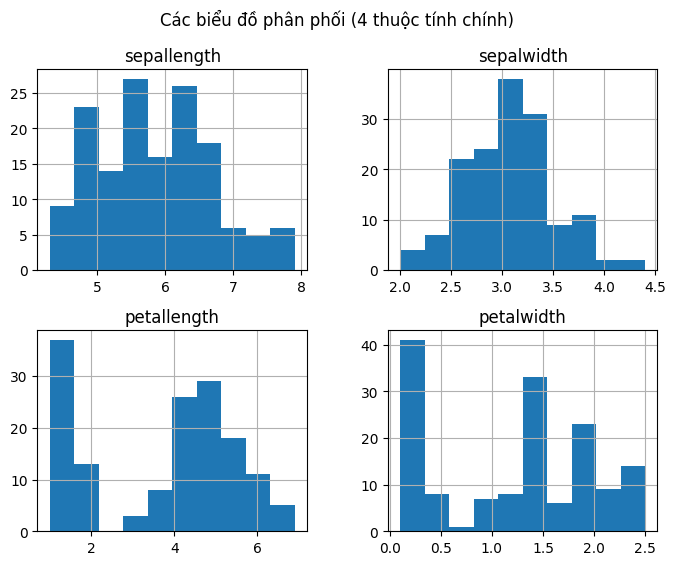

In [47]:
## Subplots
cols = ['sepallength', 'sepalwidth', 'petallength', 'petalwidth']
df[cols].hist(layout = (2, 2), figsize = (8, 6))
plt.suptitle('Các biểu đồ phân phối (4 thuộc tính chính)')

plt.show()

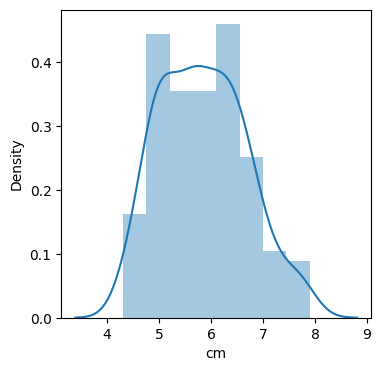

In [48]:
## Dựa trên Gaussian Kernel Density Estimate - KDE
plt.figure(figsize = (4, 4))
sbn.distplot(df['sepallength'])
plt.ylabel('Density')
plt.xlabel('cm')

plt.show()

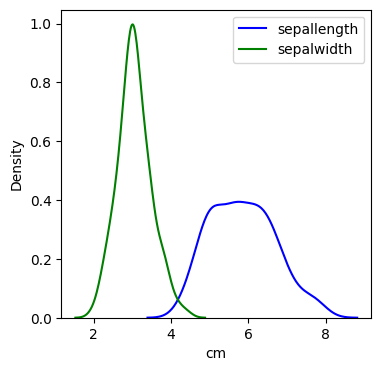

In [49]:
## Loại bỏ histogram
plt.figure(figsize = (4, 4))
sbn.distplot(df['sepallength'], hist = False, color = 'blue', label = 'sepallength')
sbn.distplot(df['sepalwidth'],  hist = False, color = 'green', label = 'sepalwidth')
plt.legend()
plt.ylabel('Density')
plt.xlabel('cm')

plt.show()

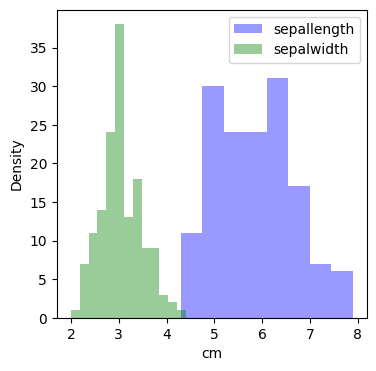

In [50]:
## Loại bỏ KDE
plt.figure(figsize = (4, 4))
sbn.distplot(df['sepallength'], kde = False, color = 'blue', label = 'sepallength')
sbn.distplot(df['sepalwidth'],  kde = False, color = 'green', label = 'sepalwidth')
plt.legend(loc = 1)
plt.ylabel('Density')
plt.xlabel('cm')

plt.show()

#####<i>BOX plot</i>

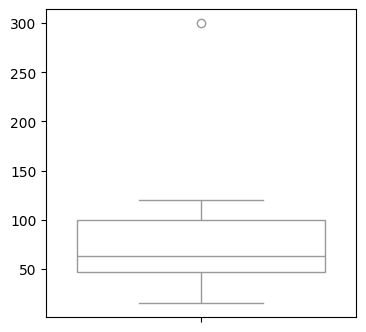

In [51]:
##------------------------------------------------------------------------------
## Biểu đồ hộp dạng ĐỨNG
##------------------------------------------------------------------------------
data = np.array([15, 45, 50, 120, 300, 34, 55, 70, 105, 85])

plt.figure(figsize = (4, 4))
sbn.boxplot(y = data, color = 'white')

plt.show()

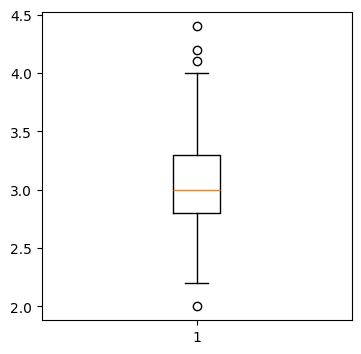

In [52]:
## Sử dụng với DataFrame
plt.figure(figsize = (4, 4))
data = df['sepalwidth']
plt.boxplot(data)

plt.show()

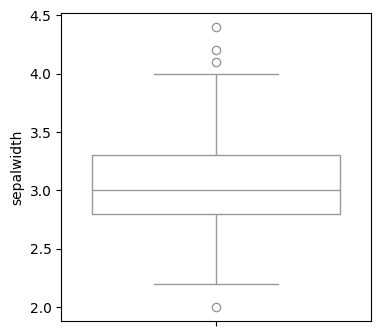

In [53]:
##------------------------------------------------------------------------------
## Biểu đồ hộp dạng nằm NGANG
##------------------------------------------------------------------------------
plt.figure(figsize = (4, 4))
sbn.boxplot(data, color = 'white')

plt.show()

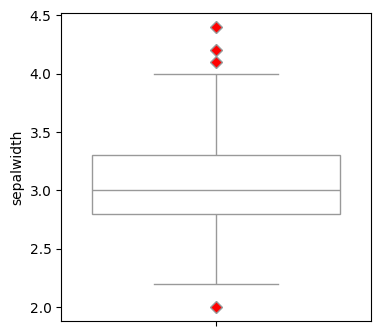

In [54]:
##------------------------------------------------------------------------------
## Chọn ký tự đặc biệt cho outliers
##------------------------------------------------------------------------------
outlier = dict(marker = 'D', markerfacecolor = 'r')

plt.figure(figsize = (4, 4))
sbn.boxplot(data, flierprops = outlier, color = 'white')

plt.show()

#####<i>SCATTER plot</i>

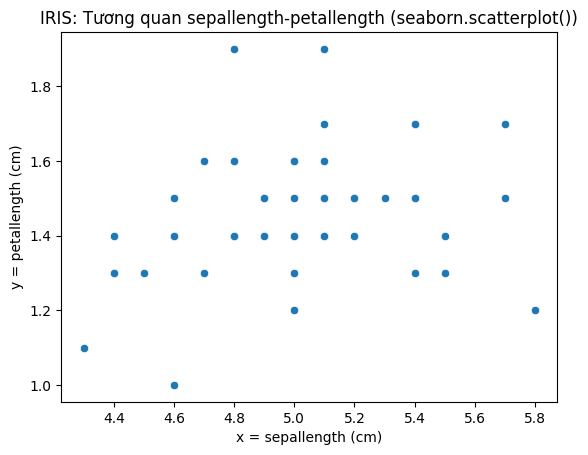

In [55]:
##------------------------------------------------------------------------------
## Biểu đồ phân tán KHÔNG phân lớp
##------------------------------------------------------------------------------
x_ = [5.1, 4.9, 4.7, 4.6, 5.0, 5.4, 4.6, 5.0, 4.4, 4.9,
     5.4, 4.8, 4.8, 4.3, 5.8, 5.7, 5.4, 5.1, 5.7, 5.1,
     5.4, 5.1, 4.6, 5.1, 4.8, 5.0, 5.0, 5.2, 5.2, 4.7,
     4.8, 5.4, 5.2, 5.5, 4.9, 5.0, 5.5, 4.9, 4.4, 5.1,
     5.0, 4.5, 4.4, 5.0, 5.1, 4.8, 5.1, 4.6, 5.3, 5.0]

y_ = [1.4, 1.4, 1.3, 1.5, 1.4, 1.7, 1.4, 1.5, 1.4, 1.5,
     1.5, 1.6, 1.4, 1.1, 1.2, 1.5, 1.3, 1.4, 1.7, 1.5,
     1.7, 1.5, 1.0, 1.7, 1.9, 1.6, 1.6, 1.5, 1.4, 1.6,
     1.6, 1.5, 1.5, 1.4, 1.5, 1.2, 1.3, 1.5, 1.3, 1.5,
     1.3, 1.3, 1.3, 1.6, 1.9, 1.4, 1.6, 1.4, 1.5, 1.4]

plt.title('IRIS: Tương quan sepallength-petallength (seaborn.scatterplot())')
plt.xlabel('x = sepallength (cm)')
plt.ylabel('y = petallength (cm)')
sbn.scatterplot(x = x_, y = y_)

plt.show()

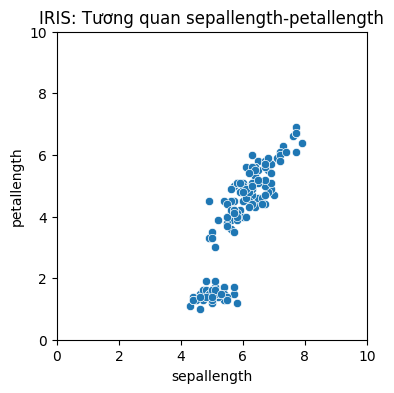

In [56]:
## Sử dụng với DataFrame
x_, y_ = df['sepallength'], df['petallength']

plt.figure(figsize = ([4, 4]))
plt.xlim(0, 10) # min, max
plt.ylim(0, 10)
plt.title('IRIS: Tương quan sepallength-petallength')
plt.xlabel('sepallength')
plt.ylabel('petallength')
sbn.scatterplot(x = x_, y = y_)

plt.show()

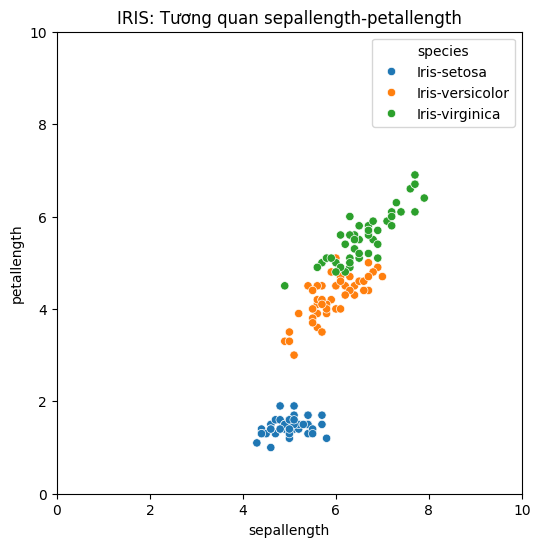

In [57]:
##------------------------------------------------------------------------------
## Biểu đồ phân tán CÓ phân lớp
##------------------------------------------------------------------------------
plt.figure(figsize = ([6, 6]))
plt.xlim(0, 10) # min, max
plt.ylim(0, 10)
plt.title('IRIS: Tương quan sepallength-petallength')
plt.xlabel('sepallength')
plt.ylabel('petallength')
sbn.scatterplot(x = x_, y = y_, data = df, hue = 'species', legend = 'full')

plt.show()

<Figure size 400x400 with 0 Axes>

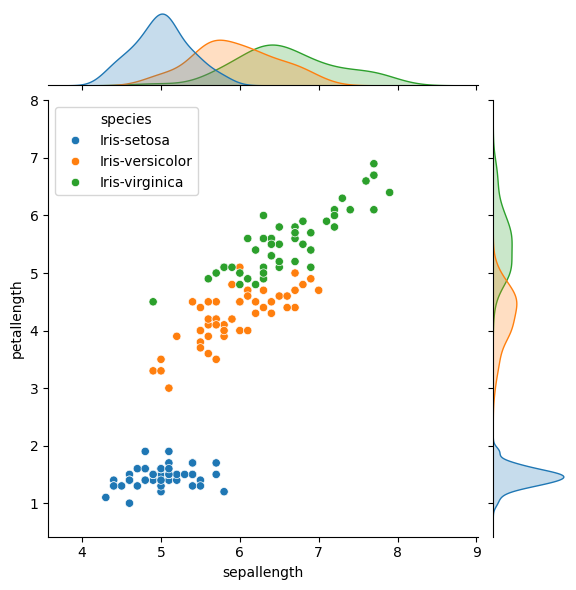

In [58]:
##------------------------------------------------------------------------------
## Sử dụng thư viện seaborn với 2 biến độc lập
##------------------------------------------------------------------------------
plt.figure(figsize = ([4, 4]))
sbn.jointplot(x = x_, y = y_, data = df, hue = 'species')

plt.show()

#####<i>HEAT MAP</i>

In [59]:
## Ma trận tương quan
corr_matrix = [[ 1.0000,  0.0862,  0.2837, -0.0842, -0.0684, -0.0265, -0.0881],
               [ 0.0862,  1.0000,  0.3276,  0.7647,  0.5876, -0.9156,  0.7516],
               [ 0.2837,  0.3276,  1.0000,  0.4413,  0.0228, -0.5441,  0.4715],
               [-0.0842,  0.7647,  0.4413,  1.0000,  0.4869, -0.8340,  0.6229],
               [-0.0684,  0.5876,  0.0228,  0.4869,  1.0000, -0.4616,  0.4398],
               [-0.0265, -0.9156, -0.5441, -0.8340, -0.4616,  1.0000, -0.8724],
               [-0.0881,  0.7516,  0.4715,  0.6229,  0.4398, -0.8724,  1.0000]]

corr_matrix = np.random.random((10, 10))

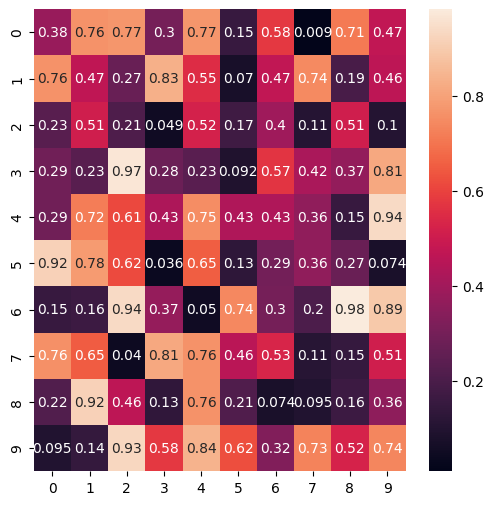

In [60]:
##------------------------------------------------------------------------------
## Biểu diễn mối tương quan
##------------------------------------------------------------------------------
plt.figure(figsize = (6, 6))
sbn.heatmap(corr_matrix, annot = True)

plt.show()

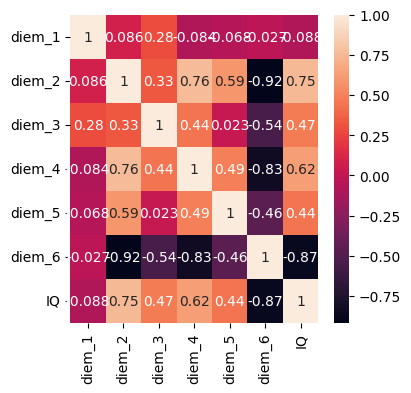

In [61]:
## Sử dụng DataFrame
df = pd.read_csv(folder + '/Data/IQ.csv')
correlation = df.corr()

fig = plt.figure(figsize = ([4, 4]))
sbn.heatmap(correlation, annot = True)

plt.show()

#####<i>Subplots</i>

In [62]:
import matplotlib as plt

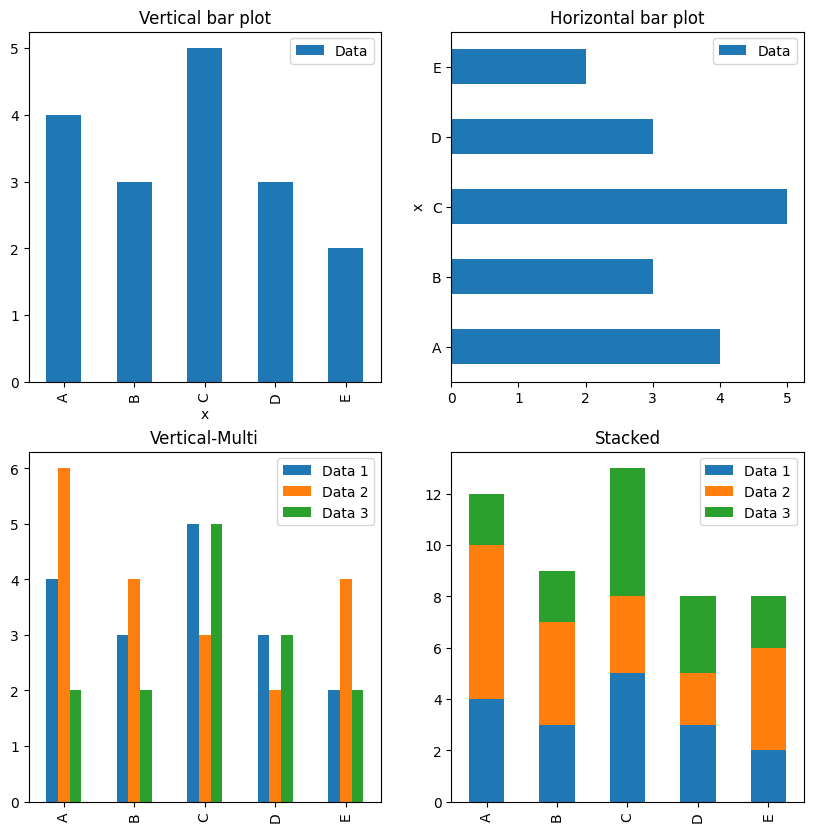

In [63]:
##------------------------------------------------------------------------------
## Sử dụng thư viện pandas
##------------------------------------------------------------------------------
x  = ['A', 'B', 'C', 'D', 'E']
y1, y2, y3 = [4, 3, 5, 3, 2], [6, 4, 3, 2, 4], [2, 2, 5, 3, 2]

fig, ((ax1, ax2),(ax3, ax4)) = plt.pyplot.subplots(2, 2, figsize = (10, 10))
df = pd.DataFrame({'x': x, 'Data': y1})
df.plot.bar(x = 'x', y = 'Data', title = 'Vertical bar plot', ax = ax1)
df.plot.barh(x = 'x', y = 'Data', title = 'Horizontal bar plot', ax = ax2)

df = pd.DataFrame({'Data 1': y1, 'Data 2': y2,'Data 3': y3}, index = x)
df.plot.bar(ax = ax3, title = 'Vertical-Multi')
df.plot.bar(ax = ax4, title = 'Stacked', stacked = True)

plt.pyplot.show()

---
#### **3. Vẽ biểu đồ với thư viện pyplot**

> Biểu đồ tương tác

---

#####<i>RADAR plot</i>

In [67]:
%pip install --upgrade nbformat

thang = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig = go.Figure()

## Dữ liệu Online
fig.add_trace(go.Scatterpolar(name  = 'Online', r = [85, 70, 90, 75, 60, 80, 85, 70, 90, 75, 60, 80],
                              theta = thang, fill='toself'))
## Dữ liệu Offline
fig.add_trace(go.Scatterpolar(name  = 'Offline', r = [70, 85, 65, 90, 80, 70, 70, 85, 65, 90, 80, 70],
                              theta = thang, fill='toself'))

## Đặt cấu hình biểu đồ
fig.update_layout(width = 500, height = 500,  # pixels
                  polar = dict(radialaxis  = dict(visible = True, range = [0, 100]),
                               angularaxis = dict(direction = "clockwise", rotation = 90)),
                  title = '<b>Biểu đồ Radar</b>', title_x = 0.5,  # 0: bên trái, 0.5: chính giữa, 1: bên phải
                  showlegend = True)
fig.show(renderer="browser")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


#####<i>AREA plot</i>

In [68]:
## Tạo dữ liệu giả lập doanh số của các sản phẩm A, B và C tại 200 mốc thời gian trong 12 tháng
tdiem = np.linspace(1, 12, 200)  ## Chia [1, 12] thành 200 mốc thời điểm

sph_a = 50 + 10 * np.sin(tdiem) + 30 * np.exp(-(tdiem - 4)**2 / 1.5) + 40 * np.exp(-(tdiem - 8.5)**2 / 1.5)
sph_b = 60 + 20 * np.cos(tdiem * 1.2)
sph_c = 40 + 15 * np.sin(tdiem / 1.5) + 2.5 * tdiem

In [70]:
##------------------------------------------------------------------------------
## Biểu đồ Overlapping Area
##------------------------------------------------------------------------------
fig = go.Figure()

## Vẽ các đường biểu diễn
fig.add_trace(go.Scatter(name    = 'A', x = tdiem, y = sph_a,
                         fill    ='tozeroy',
                         opacity = 0.4,
                         line    = dict(color = '#1f77b4', width = 2)))

fig.add_trace(go.Scatter(name    = 'B', x = tdiem, y = sph_b,
                         fill    ='tozeroy',
                         opacity = 0.4,
                         line    = dict(color = '#ff7f0e', width = 2)))

fig.add_trace(go.Scatter(name    = 'C', x = tdiem, y = sph_c,
                         fill    ='tozeroy',
                         opacity = 0.4,
                         line    = dict(color = '#2ca02c', width = 2)))

## Bổ sung các thành phần của biểu đồ
fig.update_layout(width = 1000, height = 500,  # pixels
                  title = dict(text = '<b>Biểu đồ OVERLAPPING Area</b>', x = 0.5, xanchor = 'center'),
                  xaxis_title = 'Tháng', yaxis_title = 'Giá trị sản phẩm (K$)', template = 'plotly_white')

fig.show(renderer="browser")

In [72]:
## Sử dụng Dataframe với Wide Format (PIVOT table): dùng cho go.Figure
tdiem    = pd.date_range(start = '2025-01-01', end = '2025-12-31', periods = 200)
theo_thg = np.linspace(1, 12, 200)

## Dạng Wide Format (200 hàng × 4 cột)
df = pd.DataFrame({'Thời gian' : tdiem,
                   'A': sph_a,
                   'B': sph_b,
                   'C': sph_c})

## Vẽ các đường biểu diễn
fig = go.Figure()
colors = {'A': '#1f77b4', 'B': '#ff7f0e', 'C': '#2ca02c'}

for col in ['A', 'B', 'C']:
    fig.add_trace(go.Scatter(x       = df['Thời gian'],
                             y       = df[col],
                             name    = col,
                             fill    = 'tozeroy',  # từ y = 0
                             opacity = 0.35,       # độ mờ
                             line    = dict(color = colors[col], width = 1.5)))

## Bổ sung các thành phần của biểu đồ
fig.update_layout(title       = dict(text = '<b>Biểu đồ OVERLAPPING Area</b> (PIVOT table)',
                  x           = 0.5,
                  xanchor     = 'center'),
                  yaxis_title = 'Doanh số (K$)',
                  template    = 'plotly_white')
fig.show(renderer="browser")

In [ ]:
## Sử dụng Dataframe với Long Format (FEATURES-VALUES): dùng cho Plotly Express (px)
df_long = pd.melt(df,
                  id_vars    = ['Thời gian'],
                  var_name   = 'Sản phẩm',
                  value_name = 'Doanh số')

## Vẽ các đường biểu diễn
fig = px.line(df_long,
              x     = 'Thời gian',
              y     = 'Doanh số',
              title = '<b>Biểu đồ OVERLAPPING Area</b> (FEATURES-VALUES)',
              color = 'Sản phẩm',
              color_discrete_sequence=['#1f77b4', '#ff7f0e', '#2ca02c'])

## Tô mầu các miền từ trục hoàng y = 0
fig.update_traces(fill = 'tozeroy', opacity = 0.35)

## Bổ sung các thành phần của biểu đồ
fig.update_layout(title_x     = 0.5,  # canh giữa tiêu đề
                  xaxis_title = '',
                  yaxis_title = 'Doanh số (K$)',
                  template    ='plotly_white')
fig.show()

In [ ]:
##------------------------------------------------------------------------------
## Biểu đồ Stacked Area
##------------------------------------------------------------------------------
fig = go.Figure()

## Vẽ các đường biểu diễn chồng lên nhau (gán chung stackgroup = 'one')
fig.add_trace(go.Scatter(x    = tdiem,
                         y    = sph_a,
                         name = 'A',
                         mode = 'lines',
                         line = dict(color='#1f77b4'),
                         stackgroup ='one'))

fig.add_trace(go.Scatter(x    = tdiem,
                         y    = sph_b,
                         name = 'B',
                         mode = 'lines',
                         line = dict(color='#ff7f0e'),
                         stackgroup ='one'))

fig.add_trace(go.Scatter(x    = tdiem,
                         y    = sph_c,
                         name = 'C',
                         mode = 'lines',
                         line = dict(color='#2ca02c'),
                         stackgroup ='one'))

## Bổ sung các thành phần của biểu đồ
fig.update_layout(title = dict(text = '<b>Biểu đồ STACKED Area</b>', x = 0.5, xanchor = 'center'),
                  yaxis_title = 'Tổng doanh số (A + B + C)',
                  template    = 'plotly_white')
fig.show(renderer="browser")

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [77]:
## Sử dụng Dataframe với Long Format (FEATURES-VALUES): dùng cho Plotly Express (px)
N = len(tdiem)  # Số lượng mẫu của mỗi sản phẩm (200)

df = pd.DataFrame({'Tháng'   : np.tile(tdiem, 3),  # lặp lại 3 lần cho A, B và C
                   'Sản phẩm': ['A'] * N + ['B'] * N + ['C'] * N,
                   'Doanh số': np.concatenate([sph_a, sph_b, sph_c])})

## Vẽ các đường biểu diễn
fig = px.area(df,
               x     = 'Tháng',
               y     = 'Doanh số',
               title = '<b>Biểu đồ STACKED Area</b> (FEATURES-VALUES)',
               color = 'Sản phẩm',
               color_discrete_sequence=['#1f77b4', '#ff7f0e', '#2ca02c'])

## Bổ sung các thành phần của biểu đồ
fig.update_layout(xaxis_title = '',
                  title_x     = 0.5,  # canh giữa tiêu đề
                  yaxis_title = 'Doanh số (K$)',
                  template    ='plotly_white')
fig.show(renderer="browser")

In [79]:
##------------------------------------------------------------------------------
## Biểu đồ Stream Area (Wiggle)
##------------------------------------------------------------------------------
## Lưu ý: Plotly không tích hợp tham số baseline = 'wiggle' như Matplotlib
##        nên cần phải tính toán đường cơ sở Wiggle (Byron & Wattenberg)

## Thuật toán Byron & Wattenberg cho k = 3 lớp (để căn giữa toàn bộ khối diện tích)
## Công thức trọng số: -((5/6) * sph_a + (3/6) * sph_b + (1/6) * sph_c)
g0 = -((5 / 6) * sph_a + (3 / 6) * sph_b + (1 / 6) * sph_c)

fig = go.Figure()

## Vẽ đường cơ sở Wiggle ẩn (dùng để dịch chuyển khối dòng chảy vào giữa)
fig.add_trace(go.Scatter(x = tdiem, y = g0,
                         name       = 'Wiggle Baseline',
                         mode       = 'lines',
                         line       = dict(width = 0),
                         showlegend = False,
                         hoverinfo  = 'skip',
                         stackgroup = 'one'))

## Vẽ các đường biểu diễn của các sản phẩm A, B, C xếp chồng lên đường cơ sở
fig.add_trace(go.Scatter(x = tdiem, y = sph_a,
                         name       = 'A',
                         mode       = 'lines',
                         line       = dict(color = '#1f77b4'),
                         stackgroup = 'one'))

fig.add_trace(go.Scatter(x = tdiem, y = sph_b,
                         name       = 'B',
                         mode       = 'lines',
                         line       = dict(color = '#ff7f0e'),
                         stackgroup = 'one'))

fig.add_trace(go.Scatter(x = tdiem, y = sph_c,
                         name       = 'C',
                         mode       = 'lines',
                         line       = dict(color = '#2ca02c'),
                         stackgroup = 'one'))

## Bổ sung các thành phần biểu đồ
fig.update_xaxes(tickvals  = np.arange(1, 13),
                 ticktext  = [f'Th. {i}' for i in range(1, 13)],
                 tickangle = -45)

fig.update_layout(title = dict(text = '<b>Biểu đồ STREAM Area</b> (Wiggle Baseline)', x = 0.5, xanchor = 'center'),
                  xaxis_title = '',
                  yaxis_title = 'Độ biến thiên dòng chảy',
                  template    = 'plotly_white')
fig.show(renderer="browser")

#####<i>PARALLEL SETS plot</i>

In [ ]:
## Dữ liệu TITANIC
df = pd.read_csv(folder + '/Data/Titanic.csv', usecols = ['survived', 'pclass', 'sex', 'embarked'])
print(df.head())

   survived  pclass     sex embarked
0         0       3    male        S
1         1       1  female        C
2         1       3  female        S
3         1       1  female        S
4         0       3    male        S


In [80]:
##------------------------------------------------------------------------------
## Biểu diễn với thứ tự các cột CATEGORICAL sẵn có
##------------------------------------------------------------------------------
fig = px.parallel_categories(df, width = 800, height = 400)

fig.show(renderer="browser")

In [ ]:
##------------------------------------------------------------------------------
## Biểu diễn với các cột CATEGORICAL được chỉ định
##------------------------------------------------------------------------------
fig = px.parallel_categories(df,
                             dimensions = ['pclass', 'sex', 'embarked', 'survived'],
                             labels     = {'pclass': 'Hạng vé', 'sex': 'Phái', 'embarked': 'Cảng',
                                           'survived': 'Sống sót'},
                             width      = 1000, height = 500)
fig.show()

In [ ]:
##------------------------------------------------------------------------------
## Sử dụng yếu tố mầu sắc cho NUMERICAL feature
##------------------------------------------------------------------------------
colorscale = ['blue', 'cyan']
fig = px.parallel_categories(df,
                             dimensions = ['pclass', 'sex', 'embarked', 'survived'],
                             color      = 'survived', color_continuous_scale = colorscale,
                             labels     = {'sex': 'Phái', 'embarked': 'Cảng', 'pclass': 'Hạng vé', 'survived': 'Tình trạng'},
                             width      = 1000, height = 500)
fig.update_layout(coloraxis_colorbar = dict(tickvals = [0, 1],
                                            ticktext = ['0: Chết', '1: Sống sót'],
                                            tickmode = 'array'))
fig.show()

In [ ]:
##------------------------------------------------------------------------------
## Sử dụng plotly.graph_objects.parcats()
##------------------------------------------------------------------------------
## *** Bước 1: Tạo các dimensions (parallel sets)
class_dim = go.parcats.Dimension(values = df.pclass,
                                 categoryorder = 'category ascending',
                                 label = 'Hạng vé'
                                )
sex_dim   = go.parcats.Dimension(values = df.sex, label = 'Phái')
emb_dim   = go.parcats.Dimension(values = df.embarked, label = 'Cảng')
surv_dim  = go.parcats.Dimension(values = df.survived, label = 'Tình trạng',
                                 categoryarray = [0, 1],
                                 ticktext = ['Chết', 'Sống']
                                )

In [ ]:
## *** Bước 2: Tạo biểu đồ
color      = df.survived   # target variable
colorscale = [[0, 'blue'], [1, 'cyan']];

fig = go.Figure(data = [go.Parcats(dimensions = [class_dim, sex_dim, emb_dim, surv_dim],
                                   line       = {'color' : color, 'colorscale' : colorscale}                                  )
                       ]
                )
fig.update_layout(autosize = False, width = 1000, height = 500)

fig.show()